# A qubit's microwave chain, its network-style stack, and a bench analog for a CSUS oscilloscope
### Experimenter: Colin Casey (CSUS) · status: design, simulation and protocol. **No bench data has been taken yet.**

**In plain words.** A superconducting qubit is controlled by microwaves. To flip it you transmit a
shaped ~5 GHz burst, and to read it you receive a faint echo. That makes the control electronics an RF
**transmitter and receiver** design problem, the subject of UCLA's ECE 279AS (*RF and Microwave
Transmitter Design*), where this repo started. This notebook:

1. draws the **block diagram** from room temperature down to 15 mK;
2. stacks the **quantum computing layers** on top of the **OSI networking layers** from
   `circuits_to_qubits.ipynb`, and walks one gate down the stack to volts and back up to a bit;
3. designs each part as a 279AS problem: IQ up-conversion and image rejection, the cold
   **drive-line link budget** (dBm and thermal photons), and the **readout receiver** (Friis noise,
   single-shot fidelity);
4. designs a **qubit you can build on a CSUS bench**: two coupled LC tanks whose energy beats back
   and forth on an ordinary oscilloscope, following the same equation as a qubit's Rabi oscillation.
   Every prediction is computed here, and empty tables wait for the measurement.

Modules: `dgs.qubit_microwave`, `dgs.qubit_analog_bench` (with `dgs.qubit_scope`, `dgs.scope_bench`,
`dgs.mutual_inductance`, `dgs.circuit_rules`). Figures use the Okabe-Ito palette, curves differ by
line style too, and each figure has a printed text description.

In [1]:
import sys, pathlib, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, matplotlib.pyplot as plt
from dgs import qubit_microwave as qm, qubit_analog_bench as qb, qubit_scope as qs, gates_to_internet as gi
from dgs.scope_bench import Scope
OI = ["#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2", "#000000"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

### Where this sits on the OUSD(R&E) Critical Technology Areas

The sheet on the wall has arrows on six areas. The honest fit of *this* notebook to each one:

| CTA (arrowed) | What here supports it | Strength |
|---|---|---|
| FutureG | IQ up/down-conversion, image rejection, link budgets, low-noise receivers: the core RF transmitter/receiver skills | strong |
| Integrated Sensing and Cyber | single-shot detection near the quantum noise limit; the checksummed network stack it sits on | moderate |
| Advanced Computing and Software | the quantum computing stack: compiler, gate, pulse, waveform | moderate |
| Human-Machine Interfaces | a scope-based lab that makes qubit dynamics visible | weak |
| Trusted AI and Autonomy | readout discrimination is a classification problem, but no ML is built here | weak |
| Directed Energy | not addressed | none |

**Quantum Science** isn't arrowed on the sheet but is the most direct match; `dgs/ousd_alignment.py`
lists it as priority 2.

## 1. Block diagram

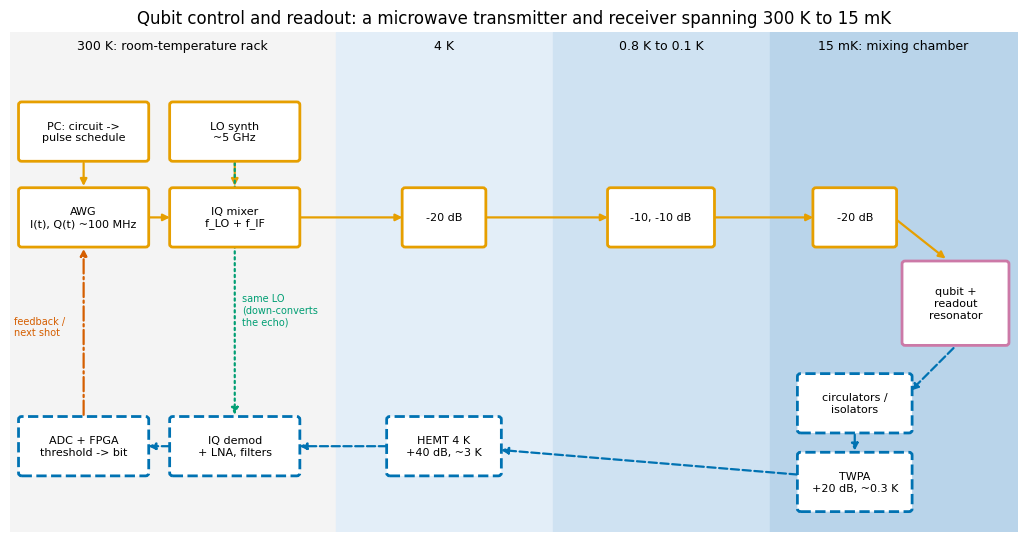

Text description: Block diagram on four temperature bands (300 K, 4 K, 0.8 to 0.1 K, 15 mK). Drive path, solid orange boxes along the top: the PC compiles a circuit into a pulse schedule, the AWG outputs I and Q envelopes near 100 MHz, an IQ mixer with a ~5 GHz LO up-converts them, then attenuators of 20 dB at 4 K, 10 + 10 dB on the intermediate plates and 20 dB at the mixing chamber cool the line before it reaches the qubit and readout resonator (pink box, bottom right of the coldest band). Readout path, dashed blue boxes along the bottom, right to left: circulators/isolators, a TWPA parametric amplifier (+20 dB, ~0.3 K noise), a 4 K HEMT (+40 dB, ~3 K), then IQ demodulation with the same LO (dotted green link), and an ADC/FPGA that thresholds the signal into a bit; a dash-dot vermillion arrow closes the loop for feedback or the next shot.


In [2]:
fig, ax = plt.subplots(figsize=(13, 6.5))
_, desc = qm.block_diagram(ax)
plt.show()
print("Text description:", desc)

## 2. The quantum stack on top of the network stack

A cloud quantum computer is reached *through* the OSI stack: your circuit travels as bytes in HTTP
over TCP/IP to the lab. There it descends a second stack that ends in microwave volts. Each quantum
layer is paired with the OSI layer it most resembles; the pairing is an analogy for organising
ideas, not a standard.

In [3]:
print(f"{'OSI (network)':34s} | quantum control stack")
print("-"*100)
for L in gi.OSI_LAYERS:
    print(f"L{L['n']} {L['name']:12s} {L['pdu']:18s} |")
print("-"*100 + "   (the circuit arrives as bytes, then descends:)")
for L in qm.QUANTUM_STACK:
    print(f"{'':34s} | Q{L['n']} {L['name']:22s} [{L['unit']:14s}] {L['example']}\n{'':34s} |    resembles {L['osi']}")

OSI (network)                      | quantum control stack
----------------------------------------------------------------------------------------------------
L7 Application  data               |
L6 Presentation data               |
L5 Session      data               |
L4 Transport    segment / datagram |
L3 Network      packet             |
L2 Data link    frame              |
L1 Physical     bit / symbol       |
----------------------------------------------------------------------------------------------------   (the circuit arrives as bytes, then descends:)
                                   | Q7 Algorithm              [problem       ] Grover search, VQE, phase estimation
                                   |    resembles L7 Application
                                   | Q6 Compiler / transpiler  [circuit       ] Qiskit transpile: map to native gates, route on the chip
                                   |    resembles L6 Presentation (re-encoding the meaning)
                    

### One X gate down the stack, and one bit back up

**Down.** The pulse-area theorem says a resonant drive rotates the qubit by
$\theta = \int \Omega(t)\,dt$, with $\Omega = \kappa V$. A Gaussian of width σ therefore needs an
amplitude $A = \theta / (\kappa \int \text{env}\,dt)$. The carrier phase picks the rotation axis:
x is all I, y is all Q. The samples are then played into a simulated qubit to confirm the rotation.

**Up.** The readout returns noisy voltages, a threshold turns each one into a bit, and the bits are
counted. It's the reverse of the trip a network frame makes up the OSI stack.

L4 gate    : Rx(3.142)
L3 pulse   : Gaussian sigma=10 ns, 2 sigma each side, amplitude 584 mV
L2 samples : 80 I/Q pairs at 2 GS/s
Bloch vector after the pulse (expect 0, 0, -1): [-0.  0. -1.]
Y/2 without DRAG -> Bloch (expect 1, 0, 0): [ 1. -0. -0.]
Y/2 with DRAG    -> Bloch: [9.998e-01 1.790e-02 3.000e-04] (the DRAG quadrature tilts a pure two-level qubit by 1.0 deg; its job, cancelling leakage to the transmon's third level, needs a three-level model, and real labs re-calibrate the amplitude with it on)
readout: 4000 shots, threshold 0.5 mV -> assignment fidelity 0.9790 (theory 0.9772 for d/sigma = 4)


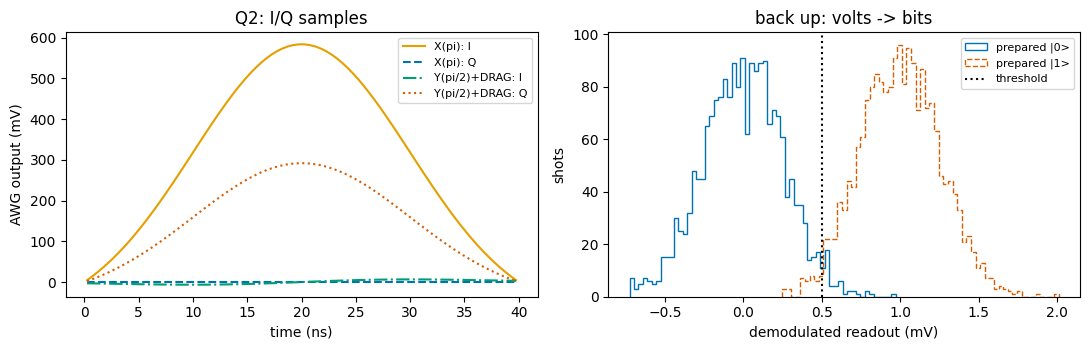

Text description: left, the AWG samples for two gates over their 40 ns duration. The solid orange X(pi) I envelope is a Gaussian peaking at 583.6 mV with the dashed blue Q flat at zero; the Y(pi/2) pulse puts its half-height Gaussian on Q (dotted vermillion, peak 291.8 mV) and its DRAG derivative on I (dash-dot green, an antisymmetric wiggle). Right, histograms of 2000 readout shots each: |0> (solid blue) centred at 0 mV, |1> (dashed vermillion) at 1 mV, with the dotted black threshold at 0.5 mV between them; the small overlap is the assignment error.


In [4]:
p = qm.compile_gate(math.pi, "x", sigma=10e-9)
for k_, v in p["layers"].items():
    print(f"{k_:11s}: {v}")
print("Bloch vector after the pulse (expect 0, 0, -1):", np.round(qm.simulate_iq_pulse(p), 6))
py = qm.compile_gate(math.pi/2, "y", sigma=10e-9, drag_beta=0.5)
bx = qm.simulate_iq_pulse(py); b0 = qm.simulate_iq_pulse(qm.compile_gate(math.pi/2, "y", sigma=10e-9))
print("Y/2 without DRAG -> Bloch (expect 1, 0, 0):", np.round(b0, 6))
print("Y/2 with DRAG    -> Bloch:", np.round(bx, 4), f"(the DRAG quadrature tilts a pure two-level qubit by {math.degrees(math.atan2(bx[1], bx[0])):.1f} deg;"
      " its job, cancelling leakage to the transmon's third level, needs a three-level model, and real labs re-calibrate the amplitude with it on)")
rng = np.random.default_rng(3)
shots = np.r_[qs.single_shots(0.0, 2000, 0, 1e-3, 2.5e-4, rng), qs.single_shots(1.0, 2000, 0, 1e-3, 2.5e-4, rng)]
truth = np.r_[np.zeros(2000), np.ones(2000)]
bits = (shots > 0.5e-3).astype(int)
print(f"readout: 4000 shots, threshold 0.5 mV -> assignment fidelity {np.mean(bits == truth):.4f} "
      f"(theory {1 - 0.5*math.erfc(4/(2*math.sqrt(2))):.4f} for d/sigma = 4)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(p["t"]*1e9, p["I"]*1e3, "-", color=OI[0], label="X(pi): I")
ax[0].plot(p["t"]*1e9, p["Q"]*1e3, "--", color=OI[5], label="X(pi): Q")
ax[0].plot(py["t"]*1e9, py["I"]*1e3, "-.", color=OI[2], label="Y(pi/2)+DRAG: I")
ax[0].plot(py["t"]*1e9, py["Q"]*1e3, ":", color=OI[3], label="Y(pi/2)+DRAG: Q")
ax[0].set_xlabel("time (ns)"); ax[0].set_ylabel("AWG output (mV)"); ax[0].legend(fontsize=8); ax[0].set_title("Q2: I/Q samples")
ax[1].hist(shots[:2000]*1e3, 60, histtype="step", ls="-", color=OI[5], label="prepared |0>")
ax[1].hist(shots[2000:]*1e3, 60, histtype="step", ls="--", color=OI[3], label="prepared |1>")
ax[1].axvline(0.5, ls=":", color=OI[6], label="threshold")
ax[1].set_xlabel("demodulated readout (mV)"); ax[1].set_ylabel("shots"); ax[1].legend(fontsize=8); ax[1].set_title("back up: volts -> bits")
plt.tight_layout(); plt.show()
print(f"Text description: left, the AWG samples for two gates over their 40 ns duration. The solid orange X(pi) I "
      f"envelope is a Gaussian peaking at {p['I'].max()*1e3:.1f} mV with the dashed blue Q flat at zero; the Y(pi/2) "
      f"pulse puts its half-height Gaussian on Q (dotted vermillion, peak {py['Q'].max()*1e3:.1f} mV) and its DRAG "
      "derivative on I (dash-dot green, an antisymmetric wiggle). Right, histograms of 2000 readout shots each: |0> "
      "(solid blue) centred at 0 mV, |1> (dashed vermillion) at 1 mV, with the dotted black threshold at 0.5 mV "
      "between them; the small overlap is the assignment error.")

## 3. Transmitter: IQ up-conversion and image rejection (the 279AS core)

The AWG plays $I = \cos\omega_{IF}t$ and $Q = \sin\omega_{IF}t$. An ideal IQ mixer outputs
$I\cos\omega_{LO}t - Q\sin\omega_{LO}t = \cos(\omega_{LO}+\omega_{IF})t$: one clean sideband. A
gain mismatch $g$ and phase error φ leave an image at $f_{LO} - f_{IF}$, and DC offsets leak the LO
itself. The image tone is a problem because it can drive a neighbouring qubit or a higher transmon
level.

ideal mixer                               : wanted   0.00 dB, image  -277.4 dB, LO leak  -277.7 dB
g = 1.05, phi = 3 deg, 10 mV DC offsets   : wanted   0.21 dB, image   -28.7 dB, LO leak   -37.0 dB   | formula IRR 28.93 dB, measured 28.93 dB


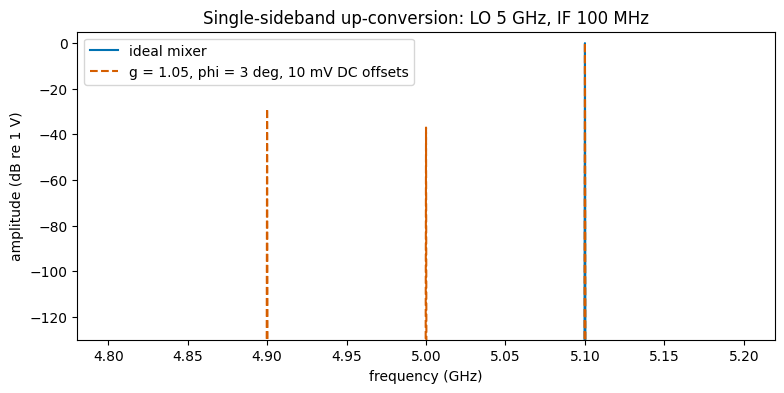

Text description: spectrum between 4.8 and 5.2 GHz. The solid blue ideal mixer shows one line at 5.1 GHz near 0 dB and nothing else above the numerical floor. The dashed vermillion imperfect mixer shows the same wanted line plus an image at 4.9 GHz about 29 dB down and an LO leak at 5.0 GHz about 37 dB down.

IRR (dB) table:   phase error ->  0.5 deg   1 deg   3 deg
   gain 1.01              43.6     40.0     31.5
   gain 1.03              36.2     35.3     30.4
   gain 1.10              26.4     26.3     25.3


In [5]:
t = np.arange(0, 2e-6, 1/40e9)
fi, flo = 100e6, 5.0e9
I, Q = np.cos(2*np.pi*fi*t), np.sin(2*np.pi*fi*t)
cases = [("ideal mixer", 1.0, 0.0, 0.0, 0.0, "-", OI[5]), ("g = 1.05, phi = 3 deg, 10 mV DC offsets", 1.05, math.radians(3), 0.01, 0.01, "--", OI[3])]
fig, ax = plt.subplots(figsize=(9, 4))
freqs = np.fft.rfftfreq(t.size, t[1]-t[0])
for lab, g, ph, di, dq, ls, c in cases:
    rf = qm.iq_upconvert(t, I, Q, flo, g, ph, di, dq)
    spec = 2*np.abs(np.fft.rfft(rf))/t.size
    m = (freqs > 4.8e9) & (freqs < 5.2e9)
    ax.plot(freqs[m]/1e9, 20*np.log10(spec[m] + 1e-12), ls, color=c, label=lab)
    usb, lsb, lo = (qm.tone_amplitude(rf, t, f) for f in (flo+fi, flo-fi, flo))
    print(f"{lab:42s}: wanted {20*np.log10(usb):6.2f} dB, image {20*np.log10(lsb+1e-15):7.1f} dB, LO leak {20*np.log10(lo+1e-15):7.1f} dB"
          + (f"   | formula IRR {qm.image_rejection_db(g, ph):.2f} dB, measured {20*np.log10(usb/lsb):.2f} dB" if lsb > 1e-9 else ""))
ax.set_xlabel("frequency (GHz)"); ax.set_ylabel("amplitude (dB re 1 V)"); ax.set_ylim(-130, 5); ax.legend(); ax.set_title("Single-sideband up-conversion: LO 5 GHz, IF 100 MHz")
plt.show()
print("Text description: spectrum between 4.8 and 5.2 GHz. The solid blue ideal mixer shows one line at 5.1 GHz near 0 dB "
      "and nothing else above the numerical floor. The dashed vermillion imperfect mixer shows the same wanted line plus "
      "an image at 4.9 GHz about 29 dB down and an LO leak at 5.0 GHz about 37 dB down.")
print("\nIRR (dB) table:   phase error ->  0.5 deg   1 deg   3 deg")
for g in (1.01, 1.03, 1.1):
    print(f"   gain {g:4.2f}           " + "  ".join(f"{qm.image_rejection_db(g, math.radians(p_)):7.1f}" for p_ in (0.5, 1, 3)))

## 4. The cold drive line: link budget in dBm *and* photons

Each attenuator at temperature $T$ passes a fraction $A$ of the hot noise and adds $(1-A)$ of its own
thermal occupation, $n_{out} = A\,n_{in} + (1-A)\,n_{th}(T)$. The power budget is ordinary dB
arithmetic. The photon budget is why the attenuators sit on the *cold* plates.

stage                    T (K)  power (dBm)  thermal photons  T_eff (K)
source                     300        -10.0             1250        300
cables, room temp          300        -16.0             1250        300
4 K plate                    4        -36.0            28.51       6.96
still (~0.8 K)             0.8        -46.0            5.424       1.42
cold plate (~0.1 K)        0.1        -56.0           0.6322      0.253
mixing chamber           0.015        -76.0         0.006322     0.0473

same 66 dB of attenuation but all at room temperature: n_th = 1250 photons (no cooling at all)
if the qubit's coupling gives Omega/2pi = 20 MHz at -76 dBm (illustrative), kappa = 2.51e+12 rad/s/V; pi pulse 25 ns (square)


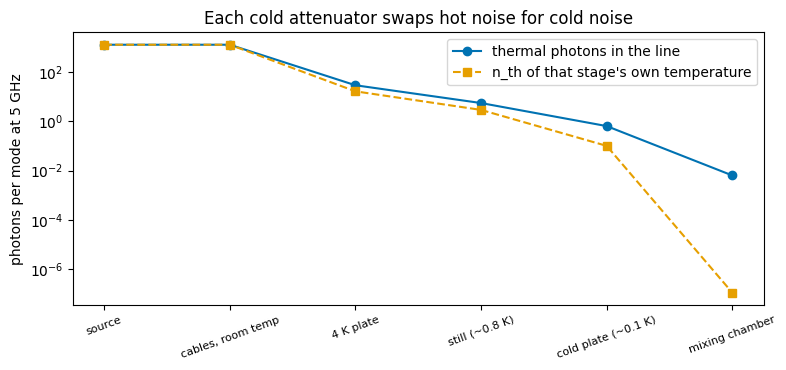

Text description: photon occupation at 5 GHz after each stage on a log axis. The solid blue line falls from about 1250 at the room-temperature source to 0.00632 at the mixing chamber; the dashed orange line shows each stage's own thermal occupation, which the blue line approaches but never goes below, so most of the cooling comes from the coldest, largest attenuators.


In [6]:
f = 5e9
rows = qm.drive_line(-10, f)
print(f"{'stage':22s} {'T (K)':>7s} {'power (dBm)':>12s} {'thermal photons':>16s} {'T_eff (K)':>10s}")
for r_ in rows:
    print(f"{r_['stage']:22s} {r_['T_K']:7.3g} {r_['p_dbm']:12.1f} {r_['n_th']:16.4g} {qm.effective_temperature(r_['n_th'], f):10.3g}")
warm = qm.drive_line(-10, f, [("same 66 dB, all at 300 K", 66.0, 300.0)])
print(f"\nsame 66 dB of attenuation but all at room temperature: n_th = {warm[-1]['n_th']:.0f} photons (no cooling at all)")
kappa = 2*np.pi*20e6/qm.vpeak_from_dbm(-76)
print(f"if the qubit's coupling gives Omega/2pi = 20 MHz at -76 dBm (illustrative), kappa = {kappa:.3g} rad/s/V; "
      f"pi pulse {math.pi/(2*np.pi*20e6)*1e9:.0f} ns (square)")
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(rows))
ax.semilogy(x, [r_["n_th"] for r_ in rows], "o-", color=OI[5], label="thermal photons in the line")
ax.semilogy(x, [qm.thermal_photons(f, r_["T_K"]) + 1e-12 for r_ in rows], "s--", color=OI[0], label="n_th of that stage's own temperature")
ax.set_xticks(x); ax.set_xticklabels([r_["stage"] for r_ in rows], rotation=20, fontsize=8)
ax.set_ylabel("photons per mode at 5 GHz"); ax.legend(); ax.set_title("Each cold attenuator swaps hot noise for cold noise")
plt.tight_layout(); plt.show()
print("Text description: photon occupation at 5 GHz after each stage on a log axis. The solid blue line falls from about "
      f"1250 at the room-temperature source to {rows[-1]['n_th']:.3g} at the mixing chamber; the dashed orange line shows each "
      "stage's own thermal occupation, which the blue line approaches but never goes below, so most of the cooling "
      "comes from the coldest, largest attenuators.")

## 5. The readout receiver: Friis and single-shot fidelity

The echo difference between $|0\rangle$ and $|1\rangle$ is tiny (here −125 dBm, illustrative), so the
first amplifier sets the noise floor. A matched filter integrating for τ separates the two states by
$d/\sigma = \sqrt{2E/N_0}$ with $E = P\tau$ and $N_0 = k_BT_{sys}$. The qubit decays during that
time, though: a longer τ buys SNR but costs $T_1$ errors.

T_sys with TWPA first: 0.330 K;  HEMT first: 3.01 K  (quantum limit hf/2k at 7 GHz = 0.168 K)
TWPA + HEMT : tau for 99 % (noise only) =   156.0 ns;  best total error 0.0020 at tau = 343 ns with T1 = 50 us
HEMT only   : tau for 99 % (noise only) =  1422.4 ns;  best total error 0.0127 at tau = 2085 ns with T1 = 50 us


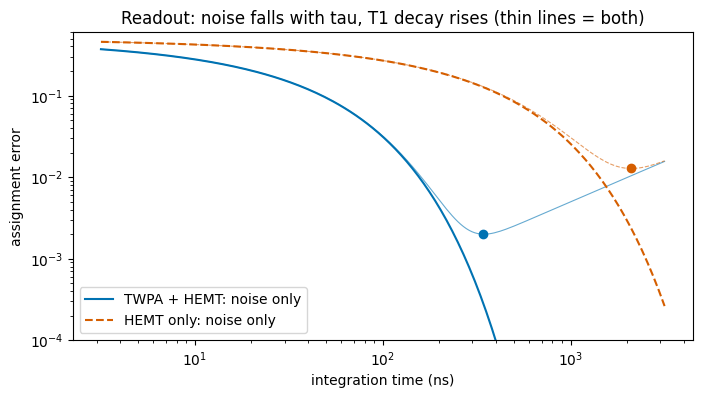

Text description: log-log assignment error against integration time. The thick solid blue (TWPA) and dashed vermillion (HEMT only) curves fall steeply with integration time; the HEMT-only curve needs about ten times longer for the same error. Thin lines of the same style add a T1 = 50 us decay term that grows with time, giving a minimum (filled circles): the TWPA reaches a much lower best error, at a much shorter integration time.


In [7]:
T_full = qm.friis_temperature(qm.DEFAULT_READOUT_AMPS)
T_no = qm.friis_temperature(qm.DEFAULT_READOUT_AMPS[1:])
print(f"T_sys with TWPA first: {T_full:.3f} K;  HEMT first: {T_no:.2f} K  (quantum limit hf/2k at 7 GHz = {qm.H*7e9/(2*qm.KB):.3f} K)")
taus = np.logspace(-8.5, -5.5, 200)
T1 = 50e-6
fig, ax = plt.subplots(figsize=(8, 4))
for T, ls, c, lab in ((T_full, "-", OI[5], "TWPA + HEMT"), (T_no, "--", OI[3], "HEMT only")):
    err = np.array([qm.readout_fidelity(-125, tau, T)["error"] for tau in taus])
    tot = err + (1 - np.exp(-taus/(2*T1)))/2
    ax.loglog(taus*1e9, err, ls, color=c, label=f"{lab}: noise only")
    ax.loglog(taus*1e9, tot, ls, color=c, lw=0.8, alpha=0.6)
    i = np.argmin(tot)
    ax.plot(taus[i]*1e9, tot[i], "o", color=c)
    print(f"{lab:12s}: tau for 99 % (noise only) = {qm.tau_for_fidelity(-125, T, 0.99)*1e9:7.1f} ns;  best total error "
          f"{tot[i]:.4f} at tau = {taus[i]*1e9:.0f} ns with T1 = 50 us")
ax.set_ylim(1e-4, 0.6); ax.set_xlabel("integration time (ns)"); ax.set_ylabel("assignment error"); ax.legend()
ax.set_title("Readout: noise falls with tau, T1 decay rises (thin lines = both)"); plt.show()
print("Text description: log-log assignment error against integration time. The thick solid blue (TWPA) and dashed "
      "vermillion (HEMT only) curves fall steeply with integration time; the HEMT-only curve needs about ten times longer "
      "for the same error. Thin lines of the same style add a T1 = 50 us decay term that grows with time, giving a "
      "minimum (filled circles): the TWPA reaches a much lower best error, at a much shorter integration time.")

## 6. A qubit analog for a CSUS teaching-lab oscilloscope

No dilution fridge is needed for the *dynamics*. Two LC tanks coupled through the mutual inductance
of two air-core coils obey, in the slowly-varying-envelope limit, the same $2\times2$ equation as a
driven qubit. Kick tank 1 and its energy moves to tank 2 and back: a Rabi oscillation at
$\Omega \approx k\omega_0$. Detune tank 2 and the transfer drops as $\Omega^2/(\Omega^2+\Delta^2)$.

**The analogy is classical.** There is no superposition of outcomes, no collapse, no entanglement. What
transfers is the equation of motion, and with it the intuition for Rabi oscillations, detuning and
avoided crossings.

In [8]:
for a, b_ in qb.ANALOGY:
    print(f"  {a:42s} <->  {b_}")

  tank 1 energy fraction                     <->  population of |0>
  tank 2 energy fraction                     <->  population of |1>
  coupling k (mutual inductance M = k L)     <->  drive strength, Omega ~ k omega0
  tank 2 tuned away (extra C)                <->  detuning Delta
  ring-down, energy time constant L / r      <->  T1-like energy decay
  energy beat between tanks on the scope     <->  Rabi oscillation
  mode splitting vs detuning                 <->  avoided crossing in qubit spectroscopy


### 6a. Design: coils, capacitors, coupling vs spacing

* **Coils:** 20 mm radius, 30 turns of AWG-24 (0.51 mm), 20 mm long, wound on a plastic former.
* **Capacitors:** 3.3 nF C0G or polypropylene film, chosen for low loss.
* **Coupling:** set k by the gap between the coil ends. The filament-loop formulas from
  `dgs.mutual_inductance` predict it, and an LCR meter checks it with the series aiding/opposing
  recipe $M = (L_\text{aid}-L_\text{opp})/4$.

coil L = 36.2 uH, f0 = 460 kHz, R_dc = 0.31 ohm, skin-effect estimate at f0 = 0.41 ohm (proximity effect makes it worse: plan on Q ~ 100-250; measure it)


Q (estimate) = 255,  energy ring-down time L/r = 88 us
10x probe (10 MOhm || 12 pF, typical): f shifts -0.18 %, probe-limited Q 95602 -> negligible
kick: 10 V generator edge through 10 pF -> 30 mV on the tank

gap (mm):      3      5      8     10     15     20     30     40     60
k:         0.251  0.215  0.173  0.150  0.109  0.081  0.047  0.030  0.014
swap (us):   4.3    5.1    6.3    7.2   10.0   13.5   23.0   36.7   79.8


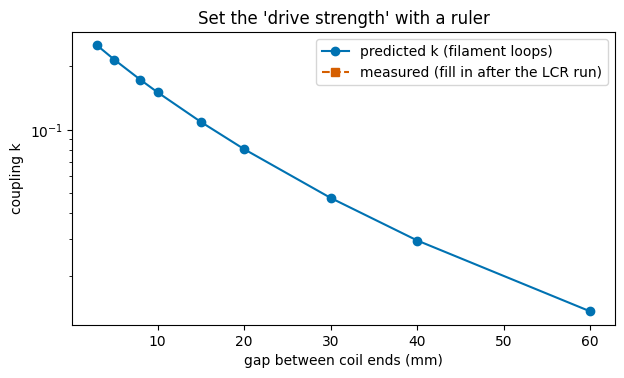

Text description: predicted coupling against gap on a log axis, blue circles joined by a solid line, falling from 0.25 at 3 mm to 0.014 at 60 mm. The legend reserves a dashed vermillion square series for the measured values, which do not exist yet.


In [9]:
R_c, N_c, len_c, aw = 0.02, 30, 0.02, 0.255e-3
gaps = np.array([3, 5, 8, 10, 15, 20, 30, 40, 60])*1e-3
cps = [qb.coil_pair_coupling(R_c, N_c, len_c, aw, g) for g in gaps]
Lc = cps[0]["L"]; Cc = 3.3e-9
f0 = 1/(2*math.pi*math.sqrt(Lc*Cc))
r_dc = qb.wire_resistance(R_c, N_c, aw); r_ac = qb.wire_resistance(R_c, N_c, aw, f0)
print(f"coil L = {Lc*1e6:.1f} uH, f0 = {f0/1e3:.0f} kHz, R_dc = {r_dc:.2f} ohm, skin-effect estimate at f0 = {r_ac:.2f} ohm "
      f"(proximity effect makes it worse: plan on Q ~ 100-250; measure it)")
print(f"Q (estimate) = {2*math.pi*f0*Lc/r_ac:.0f},  energy ring-down time L/r = {Lc/r_ac*1e6:.0f} us")
pr = qb.probe_loading(Lc, Cc)
print(f"10x probe (10 MOhm || 12 pF, typical): f shifts {pr['shift_frac']*100:.2f} %, probe-limited Q {pr['Q_probe']:.0f} -> negligible")
kick = qb.capacitive_kick(10, 10e-12, Cc)
print(f"kick: 10 V generator edge through 10 pF -> {kick*1e3:.0f} mV on the tank")
print("\ngap (mm):  " + "  ".join(f"{g*1e3:5.0f}" for g in gaps))
print("k:         " + "  ".join(f"{c['k']:5.3f}" for c in cps))
print("swap (us): " + "  ".join(f"{1/(2*c['k']*f0)*1e6:5.1f}" for c in cps))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(gaps*1e3, [c["k"] for c in cps], "o-", color=OI[5], label="predicted k (filament loops)")
ax.set_xlabel("gap between coil ends (mm)"); ax.set_ylabel("coupling k"); ax.set_title("Set the 'drive strength' with a ruler")
ax.plot([], [], "s--", color=OI[3], label="measured (fill in after the LCR run)"); ax.legend()
plt.show()
print(f"Text description: predicted coupling against gap on a log axis, blue circles joined by a solid line, falling from "
      f"{cps[0]['k']:.2f} at 3 mm to {cps[-1]['k']:.3f} at 60 mm. The legend reserves a dashed vermillion square series for "
      "the measured values, which do not exist yet.")

### 6b. Predicted scope traces (simulated CSUS bench)

CH1 probes tank 1 and CH2 probes tank 2, both through 10× probes. The generator's square-wave edge
kicks tank 1 through 10 pF. The ring-down is computed exactly (matrix exponential with coil
resistance), then shown on the simulated scope (`dgs.scope_bench`) with 8-bit ADC and 1 mV noise.
**These are predictions, not measurements.**

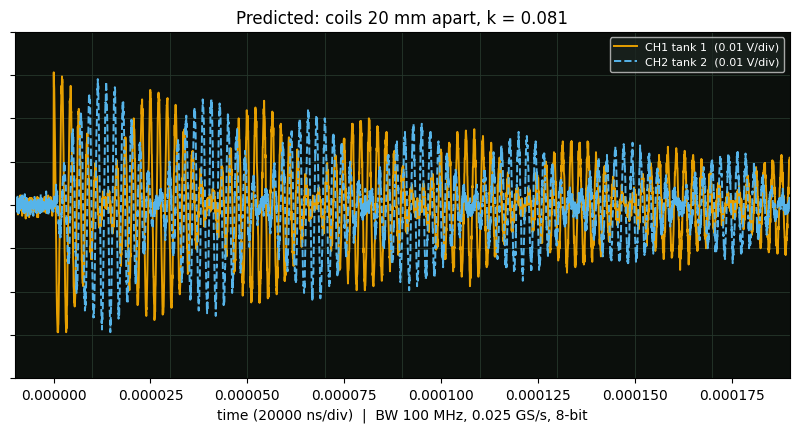

Text description: Oscilloscope screen, 10 x 8 divisions, trigger at t = 0 on CH1 (rising through 0.005 V). CH1 (tank 1, '-' line): 0.480 MHz, 0.06 Vpp; CH2 (tank 2, '--' line): 0.479 MHz, 0.0584 Vpp. Both traces are 460 kHz oscillations inside slow envelopes: CH1 (orange, solid) starts at full amplitude and pinches to nearly zero while CH2 (blue, dashed) grows from zero to full, then they swap back, every 13.5 us, the whole pattern shrinking with the coil ring-down.
analysis of the predicted scope capture: mode peaks 441.95 and 479.10 kHz -> k = 0.0805 (true 0.0806)


In [10]:
gap = 0.02
k = qb.coil_pair_coupling(R_c, N_c, len_c, aw, gap)["k"]
tt = np.arange(0, 400e-6, 2e-9)
sim = qb.simulate(tt, Lc, Cc + 12e-12, Cc + 12e-12, r_ac, k, v_kick=kick)
t_kick = 30e-6
ch = lambda v: (lambda tq: np.interp(np.asarray(tq) - t_kick, tt, v, left=0.0, right=0.0))
sc = Scope(bandwidth=100e6, sample_rate=25e6, bits=8, noise_vrms=1e-3)
sc.connect(1, "tank 1", ch(sim["v1"]), volts_per_div=0.01)
sc.connect(2, "tank 2", ch(sim["v2"]), volts_per_div=0.01)
sc.trigger(channel=1, level=0.005, slope="rising")
shot = sc.acquire(time_per_div=20e-6, pre_trigger=0.05)
fig, ax = plt.subplots(figsize=(10, 4.5))
_, desc = sc.plot(shot, ax=ax, title=f"Predicted: coils {gap*1e3:.0f} mm apart, k = {k:.3f}")
plt.show()
print("Text description:", desc, f"Both traces are {f0/1e3:.0f} kHz oscillations inside slow envelopes: CH1 (orange, solid) "
      "starts at full amplitude and pinches to nearly zero while CH2 (blue, dashed) grows from zero to full, then they swap "
      f"back, every {1/(2*k*f0)*1e6:.1f} us, the whole pattern shrinking with the coil ring-down.")
tsc = shot["t"]; v1s = shot["ch"][1]
m = tsc > 0
fl, fh = qb.fft_peaks(tsc[m], v1s[m], 2, 3e5, 7e5)
print(f"analysis of the predicted scope capture: mode peaks {fl/1e3:.2f} and {fh/1e3:.2f} kHz -> "
      f"k = {qb.k_from_mode_split(fl, fh):.4f} (true {k:.4f})")

### 6c. The qubit picture: energy fraction vs the Rabi formula, and the avoided crossing

Adding capacitance to tank 2 detunes it, which plays the role of detuning the qubit drive. The
coupled-mode (qubit) theory predicts how much energy reaches tank 2:
$P_2 = \tfrac{\Omega^2}{W^2}\sin^2(Wt/2)$, $W^2 = \Omega^2+\Delta^2$, $\Omega = k\omega_0$. Sweeping the
detuning and recording the two FFT peaks traces out the **avoided crossing** that qubit spectroscopy
shows; the minimum gap equals the coupling.

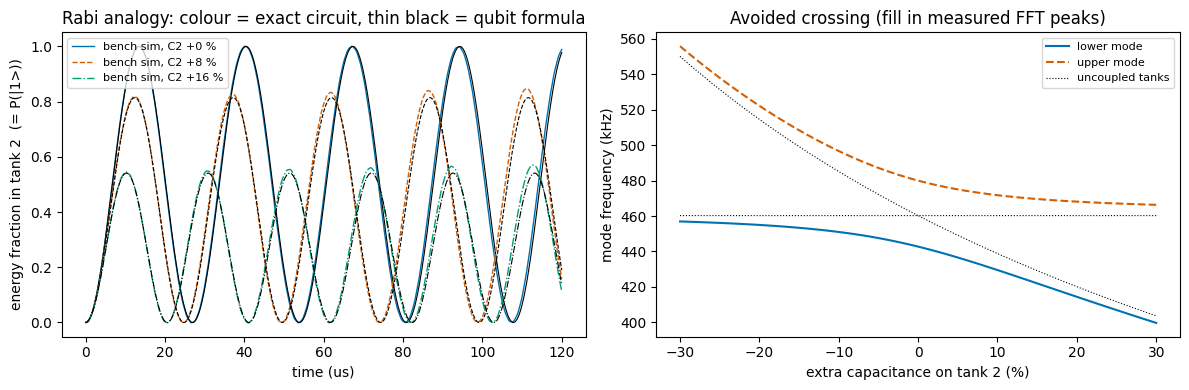

minimum splitting 37.2 kHz vs k f0 = 37.1 kHz
C2 +  0 %: max energy fraction in tank 2 = 1.001 (circuit), 1.000 (qubit formula)
C2 +  8 %: max energy fraction in tank 2 = 0.847 (circuit), 0.814 (qubit formula)
C2 + 16 %: max energy fraction in tank 2 = 0.570 (circuit), 0.541 (qubit formula)
Text description: left, fraction of the energy in tank 2 against time for three detunings. Resonant (solid blue) swings between 0 and 1.00; with 8 % extra capacitance (dashed vermillion) it peaks at 0.85 and oscillates faster; with 16 % (dash-dot green) it peaks at 0.57, faster still. Thin black lines are the qubit Rabi formula; they follow the same rhythm, with peak heights within about 0.05 (the coupled-mode theory is first order in k). Right, the two mode frequencies against tank-2 detuning: the solid blue lower and dashed vermillion upper branches bend away from the dotted black uncoupled lines and never cross, leaving a minimum gap of 37 kHz at zero detuning.


In [11]:
tt2 = np.linspace(0, 120e-6, 24001)
w1 = 1/math.sqrt(Lc*Cc)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
styles = [("-", OI[5]), ("--", OI[3]), ("-.", OI[2])]
peak = {}
for (d, (ls, c)) in zip((0.0, 0.08, 0.16), styles):
    C2 = Cc*(1 + d)
    s_ = qb.simulate(tt2, Lc, Cc, C2, r_ac, k)
    fr = s_["E2"]/(s_["E1"] + s_["E2"])
    peak[d] = (fr.max(), qb.rabi_prediction(tt2, k, w1, 1/math.sqrt(Lc*C2)).max())
    ax[0].plot(tt2*1e6, fr, ls, color=c, lw=1.0, label=f"bench sim, C2 +{d*100:.0f} %")
    ax[0].plot(tt2*1e6, qb.rabi_prediction(tt2, k, w1, 1/math.sqrt(Lc*C2)), ls, color=OI[6], lw=0.8)
ax[0].set_xlabel("time (us)"); ax[0].set_ylabel("energy fraction in tank 2  (= P(|1>))"); ax[0].legend(fontsize=8)
ax[0].set_title("Rabi analogy: colour = exact circuit, thin black = qubit formula")
dC = np.linspace(-0.3, 0.3, 121)
modes = np.array([qb.normal_modes(Lc, Lc, Cc, Cc*(1 + d), k) for d in dC])/(2*np.pi*1e3)
modes0 = np.array([qb.normal_modes(Lc, Lc, Cc, Cc*(1 + d), 1e-6) for d in dC])/(2*np.pi*1e3)
ax[1].plot(dC*100, modes[:, 0], "-", color=OI[5], label="lower mode")
ax[1].plot(dC*100, modes[:, 1], "--", color=OI[3], label="upper mode")
ax[1].plot(dC*100, modes0[:, 0], ":", color=OI[6], lw=0.8, label="uncoupled tanks")
ax[1].plot(dC*100, modes0[:, 1], ":", color=OI[6], lw=0.8)
ax[1].set_xlabel("extra capacitance on tank 2 (%)"); ax[1].set_ylabel("mode frequency (kHz)"); ax[1].legend(fontsize=8)
ax[1].set_title("Avoided crossing (fill in measured FFT peaks)")
plt.tight_layout(); plt.show()
gapmin = (modes[:, 1] - modes[:, 0]).min()
print(f"minimum splitting {gapmin:.1f} kHz vs k f0 = {k*f0/1e3:.1f} kHz")
for d, (sim_max, th_max) in peak.items():
    print(f"C2 +{d*100:3.0f} %: max energy fraction in tank 2 = {sim_max:.3f} (circuit), {th_max:.3f} (qubit formula)")
print("Text description: left, fraction of the energy in tank 2 against time for three detunings. Resonant (solid blue) "
      f"swings between 0 and {peak[0.0][0]:.2f}; with 8 % extra capacitance (dashed vermillion) it peaks at {peak[0.08][0]:.2f} and "
      f"oscillates faster; with 16 % (dash-dot green) it peaks at {peak[0.16][0]:.2f}, faster still. Thin black lines are the "
      "qubit Rabi formula; they follow the same rhythm, with peak heights within about 0.05 (the coupled-mode theory is "
      "first order in k). Right, the two mode frequencies against tank-2 detuning: the solid blue lower and "
      "dashed vermillion upper branches bend away from the dotted black uncoupled lines and never cross, leaving a minimum "
      f"gap of {gapmin:.0f} kHz at zero detuning.")

### 6d. Measurement tables (empty until the bench run)

`MEASURED` stays `None` until there is data, and nothing in this notebook pretends otherwise. Fill in
the values after the CSUS run, following the protocol in `docs/csus_qubit_analog_lab.md`, and re-run:
the cell below then compares them with the predictions.

In [12]:
MEASURED = None
# Example of the format (replace with real readings):
# MEASURED = {"L1_uH": 35.9, "L2_uH": 36.4, "L_aid_uH": ..., "L_opp_uH": ..., "gap_mm": 20,
#             "f_low_kHz": ..., "f_high_kHz": ..., "swap_us": ..., "ringdown_us": ...}
if MEASURED is None:
    print("No bench data yet. Predictions to compare against at a 20 mm gap:")
    wl, wh = qb.normal_modes(Lc, Lc, Cc + 12e-12, Cc + 12e-12, k)
    print(f"  L1 = L2 = {Lc*1e6:.1f} uH, k = {k:.3f}, M = {k*Lc*1e6:.2f} uH -> L_aid = {(2*Lc + 2*k*Lc)*1e6:.1f} uH, "
          f"L_opp = {(2*Lc - 2*k*Lc)*1e6:.1f} uH")
    print(f"  mode peaks {wl/2/np.pi/1e3:.1f} and {wh/2/np.pi/1e3:.1f} kHz, energy swap every {1/(2*k*f0)*1e6:.1f} us, "
          f"ring-down L/r ~ {Lc/r_ac*1e6:.0f} us (r uncertain)")
else:
    M_meas = (MEASURED["L_aid_uH"] - MEASURED["L_opp_uH"])/4
    k_lcr = M_meas/math.sqrt(MEASURED["L1_uH"]*MEASURED["L2_uH"])
    k_scope = qb.k_from_mode_split(MEASURED["f_low_kHz"], MEASURED["f_high_kHz"])
    print(f"k from LCR: {k_lcr:.4f};  k from scope FFT: {k_scope:.4f};  predicted: {k:.4f}")

No bench data yet. Predictions to compare against at a 20 mm gap:
  L1 = L2 = 36.2 uH, k = 0.081, M = 2.92 uH -> L_aid = 78.3 uH, L_opp = 66.6 uH
  mode peaks 441.9 and 479.1 kHz, energy swap every 13.5 us, ring-down L/r ~ 88 us (r uncertain)


## How this connects

* **Earlier notebooks.** `circuits_to_qubits.ipynb` has the OSI stack, the circuit rulebook (one test
  derives these tanks' modes, $s^2 = -1/(LC(1\pm k))$, from KCL/KVL) and the qubit-on-scope Rabi and
  Ramsey experiments. `mutual_inductance.ipynb` has $M = k\sqrt{L_1L_2}$ and the LCR recipe used in 6a.
* **Lineage.** The repo began as the ECE 279AS project (with Gabriel Morozowsky, Prof. Bahram Jalali,
  UCLA, 2024). Sections 3 to 5 are the transmitter and receiver half of that course, applied to qubits.
* **Lab protocol:** `docs/csus_qubit_analog_lab.md` (numbered steps, parts list, safety, data tables).
* **Tests:** `PYTHONPATH=. python -m pytest tests/test_qubit_microwave.py tests/test_qubit_analog_bench.py -q`.

**References** (IEEE style, written from memory; check details before citing):

[1] P. Krantz *et al.*, "A quantum engineer's guide to superconducting qubits," *Appl. Phys. Rev.*, vol. 6, no. 2, 021318, 2019.
[2] S. Krinner *et al.*, "Engineering cryogenic setups for 100-qubit scale superconducting circuit systems," *EPJ Quantum Technol.*, vol. 6, art. 2, 2019.
[3] D. M. Pozar, *Microwave Engineering*, 4th ed. Hoboken, NJ, USA: Wiley, 2012.
[4] B. Razavi, *RF Microelectronics*, 2nd ed. Upper Saddle River, NJ, USA: Prentice Hall, 2011.
[5] L. Novotny, "Strong coupling, energy splitting, and level crossings: A classical perspective," *Am. J. Phys.*, vol. 78, no. 11, pp. 1199-1202, 2010.
[6] F. Motzoi, J. M. Gambetta, P. Rebentrost, and F. K. Wilhelm, "Simple pulses for elimination of leakage in weakly nonlinear qubits," *Phys. Rev. Lett.*, vol. 103, 110501, 2009.